# data-diffusion demo: synthetic Iris

Train `TabularDiffusion` (XGBoost flow matching) on the classic Iris dataset
(150 rows, 4 numeric features + 3 species), then sample **20×** as many
synthetic rows (3,000) and compare the cluster structure.

> ⚠️ **Reminder:** synthetic output is *not* anonymization and is not
> guaranteed to be private — see the README disclaimer.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from data_diffusion import TabularDiffusion

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
iris = pd.read_csv(
    URL,
    header=None,
    names=["sepal_length", "sepal_width", "petal_length", "petal_width", "species"],
)
iris["species"] = iris["species"].str.removeprefix("Iris-")
print(iris.shape)
iris.head()


(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Original clusters

The three species form well-separated clusters, mostly along petal
measurements (setosa is fully separable; versicolor/virginica overlap a
little).

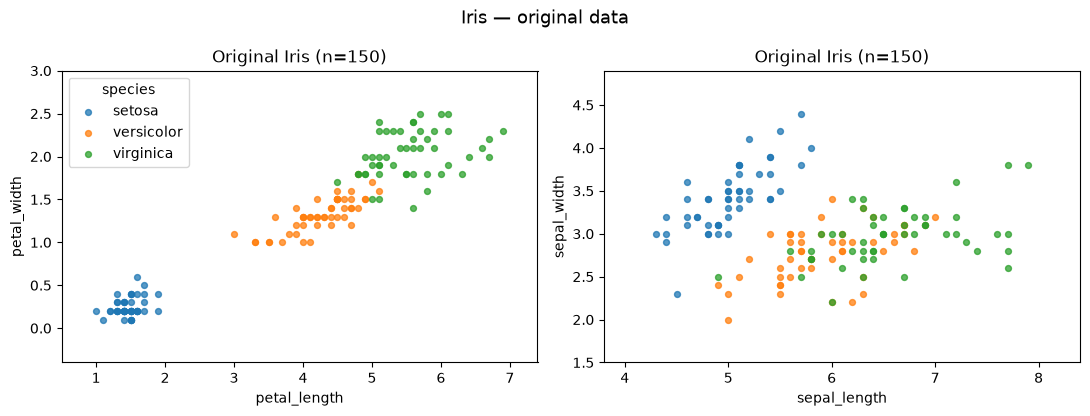

In [2]:
COLORS = {"setosa": "#1f77b4", "versicolor": "#ff7f0e", "virginica": "#2ca02c"}

def plot_clusters(df, ax, title, x, y, xlim, ylim):
    for species, color in COLORS.items():
        part = df[df["species"] == species]
        ax.scatter(part[x], part[y], s=18, alpha=0.75, color=color, label=species)
    ax.set(xlabel=x, ylabel=y, title=title, xlim=xlim, ylim=ylim)

def ranges(df):
    pad = 0.5
    lims = {}
    for col in ("sepal_length", "sepal_width", "petal_length", "petal_width"):
        lo, hi = df[col].min(), df[col].max()
        lims[col] = (lo - pad, hi + pad)
    return lims

xlims = ranges(iris)
PAIRS = [("petal_length", "petal_width"), ("sepal_length", "sepal_width")]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (x, y) in zip(axes, PAIRS):
    plot_clusters(iris, ax, f"Original Iris (n={len(iris)})", x, y, xlims[x], xlims[y])
axes[0].legend(frameon=True, title="species")
fig.suptitle("Iris — original data", fontsize=13)
fig.tight_layout()
plt.show()


## Train the model and sample 20× more rows

Defaults `n_t=50`, `K=100` — each of the 150 rows is paired with 100 Gaussian
noise draws at every flow level.

In [3]:
model = TabularDiffusion(n_t=50, K=100, n_jobs=4)
model.fit(iris)

synthetic = model.sample(3_000, seed=0)
print(synthetic.shape)
synthetic.head()


(3000, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,6.457831,2.881343,5.560137,1.876312,virginica
1,5.019345,3.199990,1.215686,0.199926,setosa
2,4.903908,2.402043,3.295715,1.000907,versicolor
3,7.037013,2.999873,5.815087,2.098319,virginica
4,5.019389,3.401262,1.461000,0.252466,setosa


## Original vs. synthetic side by side

Same axes limits on each pair so the comparison is honest.

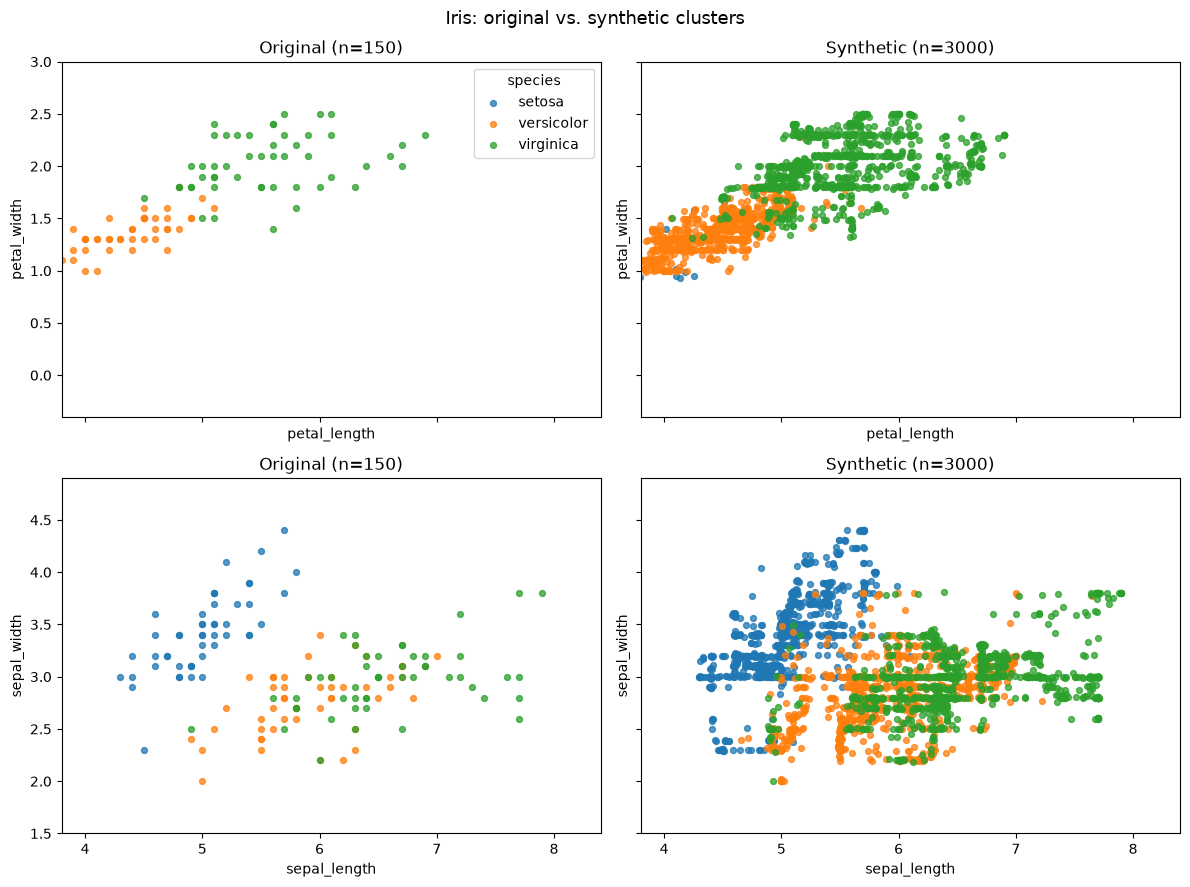

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col", sharey="row")
for row, (x, y) in enumerate(PAIRS):
    plot_clusters(
        iris, axes[row][0],
        f"Original (n={len(iris)})", x, y, xlims[x], xlims[y],
    )
    plot_clusters(
        synthetic, axes[row][1],
        f"Synthetic (n={len(synthetic)})", x, y, xlims[x], xlims[y],
    )
axes[0][0].legend(frameon=True, title="species")
fig.suptitle("Iris: original vs. synthetic clusters", fontsize=13)
fig.tight_layout()
plt.show()


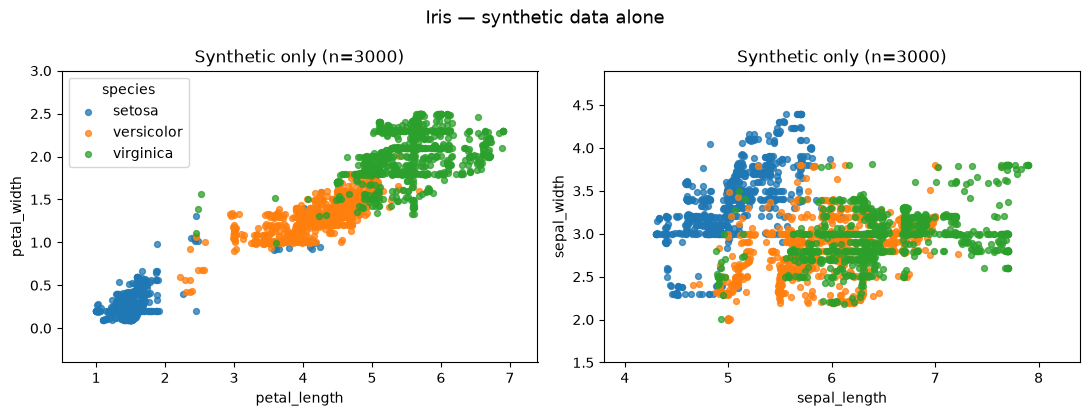

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (x, y) in zip(axes, PAIRS):
    plot_clusters(
        synthetic, ax, f"Synthetic only (n={len(synthetic)})", x, y, xlims[x], xlims[y]
    )
axes[0].legend(frameon=True, title="species")
fig.suptitle("Iris — synthetic data alone", fontsize=13)
fig.tight_layout()
plt.show()


## Quantitative check: do the properties carry over?

Per-feature means and standard deviations, and the species mix. Cluster
*shape* is what the flow is trained to preserve: within-species moments and
the versicolor/virginica boundary region should match.

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
summary = pd.DataFrame(
    {
        "orig mean": iris[features].mean(),
        "synth mean": synthetic[features].mean(),
        "orig std": iris[features].std(),
        "synth std": synthetic[features].std(),
    }
).round(3)
summary["Δ mean"] = (summary["synth mean"] - summary["orig mean"]).abs().round(3)
summary["Δ std"] = (summary["synth std"] - summary["orig std"]).abs().round(3)
summary


,orig mean,synth mean,orig std,synth std,Δ mean,Δ std
sepal_length,5.843,5.840,0.828,0.789,0.003,0.039
sepal_width,3.054,3.040,0.434,0.412,0.014,0.022
petal_length,3.759,3.781,1.764,1.694,0.022,0.070
petal_width,1.199,1.211,0.763,0.727,0.012,0.036


In [7]:
mix = pd.DataFrame(
    {
        "original": iris["species"].value_counts(normalize=True),
        "synthetic": synthetic["species"].value_counts(normalize=True),
    }
).round(3)
mix


,original,synthetic
species,,
setosa,0.333,0.317
versicolor,0.333,0.365
virginica,0.333,0.318


In [8]:
within = pd.DataFrame(
    {
        f"{sp} mean": iris.groupby("species")[features].mean().loc[sp],
        f"{sp} synth": synthetic.groupby("species")[features].mean().loc[sp],
    }
    for sp in ("versicolor", "virginica")
)
within.index.name = "feature"
within.round(3)


,versicolor mean,versicolor synth,virginica mean,virginica synth
feature,,,,
0,sepal_length 5.936 sepal_width 2.770 pe...,sepal_length 5.934154 sepal_width 2.814...,NaN,NaN
1,NaN,NaN,sepal_length 6.588 sepal_width 2.974 pe...,sepal_length 6.536457 sepal_width 2.972...
